# Optional preview · How do the weights learn?
10–15 minutes for a group already comfortable with arrays. Skip this if the core exercises need time.

## Goal
See the difference between a prediction, a loss, a gradient, and an update. Then see why fitting the known examples perfectly is not enough.

## Setup
Only NumPy and Matplotlib. Synthetic data; no downloads or GPU. This is an extension beyond the published NN Lab 1.

In [1]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 100, "animation.embed_limit": 25})
BLUE, ORANGE = "#2458a6", "#be5514"
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")

Python 3.13.5 | NumPy 2.5.3 | Matplotlib 3.11.2


## Steps
### 1. An adjustable line
Our model is `prediction = w * x + b`. Both parameters are shared by all examples. The mean squared error measures average squared prediction error.

For residual `r = w*x+b-y`, the gradients are `dw = 2*mean(r*x)` and `db = 2*mean(r)`. We subtract a small multiple of these gradients.

In [2]:
x = np.linspace(-1, 1, 25)
y = 1.5*x + .4 + np.random.default_rng(42).normal(0, .12, len(x))

def loss_and_gradient(w, b):
    residual = w*x + b - y
    return np.mean(residual**2), np.array([2*np.mean(residual*x), 2*np.mean(residual)])

def fit(learning_rate, steps=40):
    parameters = np.array([-1., -1.])
    history = [parameters.copy()]
    losses = [loss_and_gradient(*parameters)[0]]
    for _ in range(steps):
        _, gradient = loss_and_gradient(*parameters)
        parameters -= learning_rate * gradient
        history.append(parameters.copy())
        losses.append(loss_and_gradient(*parameters)[0])
    return np.array(history), np.array(losses)

history, losses = fit(.2)
print(f"MSE: {losses[0]:.4f} → {losses[-1]:.4f}")
print("Learned [w, b]:", history[-1])
assert losses[-1] < losses[0] / 100

# An independent numerical check of the analytic gradient.
parameters = np.array([.7, -.2])
epsilon = 1e-6
finite_difference = []
for direction in np.eye(2):
    high = loss_and_gradient(*(parameters + epsilon*direction))[0]
    low = loss_and_gradient(*(parameters - epsilon*direction))[0]
    finite_difference.append((high-low)/(2*epsilon))
assert np.allclose(finite_difference, loss_and_gradient(*parameters)[1], atol=1e-6)

MSE: 4.2472 → 0.0094
Learned [w, b]: [1.513 0.396]


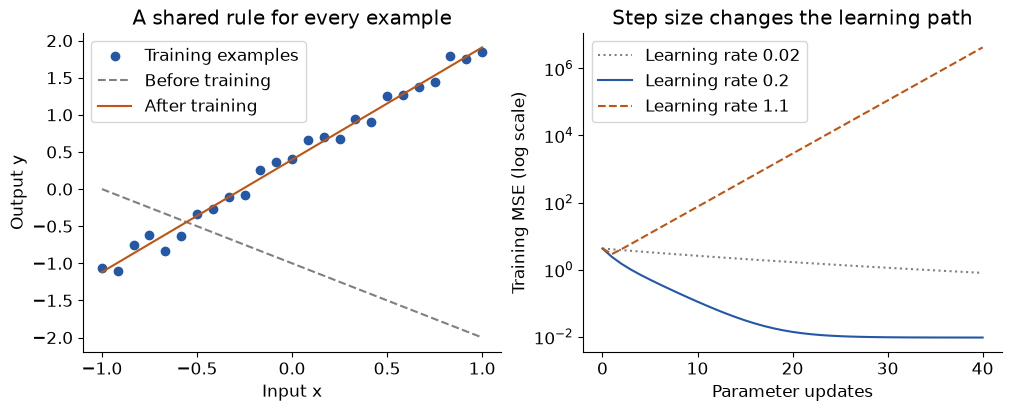

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].scatter(x, y, color=BLUE, label="Training examples")
for index, label, style in [(0, "Before training", "--"), (-1, "After training", "-")]:
    w, b = history[index]
    axes[0].plot(x, w*x+b, style, color=ORANGE if index==-1 else "gray", label=label)
axes[0].set(title="A shared rule for every example", xlabel="Input x", ylabel="Output y")
axes[0].legend()
for rate, style, color in [(.02, ":", "gray"), (.2, "-", BLUE), (1.1, "--", ORANGE)]:
    _, trial_losses = fit(rate)
    axes[1].semilogy(trial_losses, style, color=color, label=f"Learning rate {rate}")
axes[1].set(title="Step size changes the learning path", xlabel="Parameter updates", ylabel="Training MSE (log scale)")
axes[1].legend()
plt.show()

For this particular quadratic problem, 0.2 converges and 1.1 diverges. There is no universal best learning rate.

### 2. Watch predictions and loss change together
Drag the frame slider. The left panel is a function of **input x**. The right panel records loss as **parameters change**. The optimizer changes parameters, while the examples stay fixed.

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].scatter(x, y, color=BLUE)
line, = axes[0].plot(x, history[0,0]*x + history[0,1], color=ORANGE, lw=2)
axes[0].set(xlabel="Input x", ylabel="Output y", ylim=(-2.5, 2.5), title="Current model")
axes[1].plot(losses, color="lightgray")
trail, = axes[1].plot([], [], color=BLUE, lw=2)
axes[1].set(xlabel="Parameter updates", ylabel="Training MSE", xlim=(0, len(losses)-1), ylim=(0, losses.max()*1.08))
def animate_learning(frame):
    w, b = history[frame]
    line.set_ydata(w*x+b)
    trail.set_data(np.arange(frame+1), losses[:frame+1])
    axes[1].set_title(f"Update {frame}: MSE {losses[frame]:.3f}")
    return line, trail
animation = FuncAnimation(fig, animate_learning, frames=len(history), interval=140)
plt.close(fig)
display(HTML(animation.to_jshtml(default_mode="once")))

### 3. Perfect memory can fail on new inputs
Both rules below fit exactly the same three training examples. Their behaviour elsewhere differs. We constructed the second rule to illustrate the problem; no training method is being claimed here.

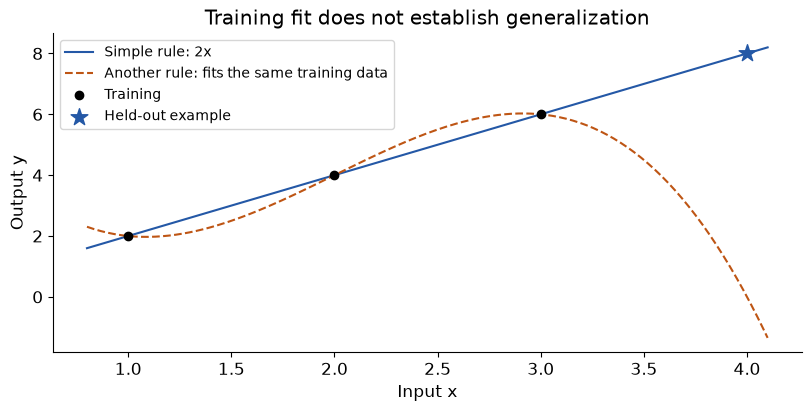

At x=4, simple rule: 8 alternative rule: 0.0


In [5]:
train_x = np.array([1., 2., 3.])
train_y = 2*train_x
heldout_x = 4.
heldout_y = 8.
def simple_rule(x):
    return 2*x
def interpolating_rule(x):
    return 2*x - (4/3)*(x-1)*(x-2)*(x-3)

assert np.allclose(simple_rule(train_x), train_y)
assert np.allclose(interpolating_rule(train_x), train_y)
grid = np.linspace(.8, 4.1, 200)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(grid, simple_rule(grid), color=BLUE, label="Simple rule: 2x")
ax.plot(grid, interpolating_rule(grid), "--", color=ORANGE, label="Another rule: fits the same training data")
ax.scatter(train_x, train_y, color="black", label="Training", zorder=4)
ax.scatter([heldout_x], [heldout_y], marker="*", s=160, color=BLUE, label="Held-out example", zorder=4)
ax.set(title="Training fit does not establish generalization", xlabel="Input x", ylabel="Output y")
ax.legend(fontsize=10)
plt.show()
print("At x=4, simple rule:", simple_rule(4), "alternative rule:", interpolating_rule(4))

## Checks
Explain which step computes predictions, which computes gradients, and which changes parameters. Backpropagation is an efficient way to compute gradients in a composed function. An optimizer uses those gradients to update parameters.

Name one way to accidentally use test information while building a model. Validation supports model choices; reserve a final test set for the final evaluation.

## Next Steps
The published NN sequence develops these ideas later. For now, master shapes and weighted sums.

- [3Blue1Brown: neural networks](https://www.3blue1brown.com/lessons/neural-networks)
- [3Blue1Brown: gradient descent](https://www.3blue1brown.com/lessons/gradient-descent)
- [Course 1](https://sites.google.com/view/rbenchea/neural-networks), especially the model/generalization example (slides 17–32).

Optional extension, prepared 2 October 2026. The learning example fits training data only and is not a reported test benchmark.